# Régression linéaire et analyse du trafic réseau
**Otmane Arajdal - laboratoire pédagogique en cybersécurité**

Ce notebook est une reconstruction du lab et de ses résultats à partir du support fourni. Il contient les 20 couples synthétiques pour fonctionner seul dans Google Colab. Les sorties ont été recalculées lors de la préparation du dépôt.

L'objectif est d'estimer un trafic attendu et d'interpréter les écarts. Il ne s'agit pas de valider un détecteur d'attaques sur du trafic réel.

Dans Colab, importer ce fichier puis exécuter toutes les cellules dans l'ordre. Les bibliothèques utilisées font partie de l'environnement scientifique habituel de Colab ; si un import manque, installer les dépendances du dépôt avant de reprendre. Les versions de l'exécution sont affichées ci-dessous.

In [1]:
import platform
import os
# Un seul thread de calcul suffit pour ce petit jeu pédagogique.
for variable in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"]:
    os.environ.setdefault(variable, "1")
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
import scipy
from IPython.display import display
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.dummy import DummyRegressor

print({"python": platform.python_version(), "numpy": np.__version__,
       "pandas": pd.__version__, "scikit-learn": sklearn.__version__,
       "scipy": scipy.__version__, "matplotlib": matplotlib.__version__})

{'python': '3.12.14', 'numpy': '2.5.4', 'pandas': '3.0.1', 'scikit-learn': '1.9.1', 'scipy': '1.18.1', 'matplotlib': '3.11.2'}


## 1. Construire et observer les données
`utilisateurs` est l'entrée X et `trafic_mbps` la cible y. Ces valeurs pédagogiques sont presque linéaires ; elles ne proviennent pas d'une collecte réseau. Aucun horodatage ni type de flux n'est disponible.

In [2]:
df = pd.DataFrame({
    "utilisateurs": [10, 15, 20, 25, 30, 35, 40, 45, 50, 55,
                     60, 65, 70, 75, 80, 85, 90, 95, 100, 105],
    "trafic_mbps": [20, 27, 35, 43, 50, 57, 66, 72, 80, 88,
                    95, 103, 110, 118, 125, 133, 140, 149, 155, 165],
})
display(df)
print("Valeurs manquantes :", int(df.isna().sum().sum()))

,utilisateurs,trafic_mbps
0,10,20
1,15,27
2,20,35
3,25,43
4,30,50
5,35,57
6,40,66
7,45,72
8,50,80
9,55,88


Valeurs manquantes : 0


## 2. Séparer puis entraîner
Le découpage reprend `test_size=0.20` et `random_state=42` du support. Le modèle apprend sur 16 points, et les métriques portent sur les 4 autres. Le split garde le test hors de l'ajustement ; il ne garantit pas à lui seul l'absence de surapprentissage ou une validation en production.

In [3]:
X = df[["utilisateurs"]]
y = df["trafic_mbps"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
model = LinearRegression().fit(X_train, y_train)
beta0 = float(model.intercept_)
beta1 = float(model.coef_[0])
print("Entraînement :", len(X_train), "| Test :", len(X_test))
print("Indices de test (base 0) :", X_test.index.tolist())
print(f"Trafic prédit = {beta0:.10f} + {beta1:.10f} x utilisateurs")

Entraînement : 16 | Test : 4
Indices de test (base 0) : [0, 17, 15, 1]
Trafic prédit = 4.6729000151 + 1.5103001056 x utilisateurs


La pente indique ici environ 1,51 Mbps supplémentaires dans la prédiction lorsque l'entrée augmente d'un utilisateur. Ce coefficient traduit une relation ajustée, pas une causalité ni la consommation de chaque utilisateur. L'intercept extrapole jusqu'à zéro utilisateur, hors de la plage de données.

## 3. Calculer les prédictions et les résidus
Le résidu signé est `trafic observé - trafic prédit`. Un résidu positif indique une sous-estimation par le modèle.

In [4]:
y_pred = model.predict(X_test)
resultats = pd.DataFrame({
    "source_row_0based": X_test.index,
    "utilisateurs": X_test["utilisateurs"].to_numpy(),
    "trafic_observe_mbps": y_test.to_numpy(),
    "trafic_predit_mbps": y_pred,
    "residu_mbps": y_test.to_numpy() - y_pred,
})
display(resultats)
plus_grand_residu = resultats.loc[resultats["residu_mbps"].abs().idxmax()]
print("Plus grand résidu absolu :")
display(plus_grand_residu.to_frame().T)

,source_row_0based,utilisateurs,trafic_observe_mbps,trafic_predit_mbps,residu_mbps
0,0,10,20,19.775901,0.224099
1,17,95,149,148.151410,0.848590
2,15,85,133,133.048409,-0.048409
3,1,15,27,27.327402,-0.327402


Plus grand résidu absolu :


,source_row_0based,utilisateurs,trafic_observe_mbps,trafic_predit_mbps,residu_mbps
1,17.0,95.0,149.0,148.15141,0.84859


## 4. Évaluer les erreurs de prédiction
MAE est en Mbps, MSE en (Mbps)², et R² est sans unité. R² n'est pas un taux de détection d'attaques. La comparaison avec une constante égale à la moyenne d'entraînement est un ajout à cette reproduction ; ce n'est pas une capture du travail initial.

In [5]:
mae = float(mean_absolute_error(y_test, y_pred))
mse = float(mean_squared_error(y_test, y_pred))
r2 = float(r2_score(y_test, y_pred))
baseline = DummyRegressor(strategy="mean").fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)
comparaison = pd.DataFrame({
    "modele": ["Régression linéaire", "Moyenne d'entraînement (ajout)"],
    "MAE_Mbps": [mae, mean_absolute_error(y_test, baseline_pred)],
    "MSE_Mbps2": [mse, mean_squared_error(y_test, baseline_pred)],
    "R2": [r2, r2_score(y_test, baseline_pred)],
})
display(comparaison)
print(f"MAE={mae:.10f} Mbps | MSE={mse:.10f} (Mbps)^2 | R2={r2:.10f}")

,modele,MAE_Mbps,MSE_Mbps2,R2
0,Régression linéaire,0.362125,0.219965,0.999937
1,Moyenne d'entraînement (ajout),58.750000,3624.828125,-0.038726


MAE=0.3621248680 Mbps | MSE=0.2199651202 (Mbps)^2 | R2=0.9999369671


## 5. Visualiser l'ajustement et les erreurs
Les couleurs distinguent l'entraînement du test. La droite est ajustée uniquement sur l'entraînement. Le second graphe montre les quatre résidus de test, sans réutiliser les points d'entraînement pour calculer les métriques.

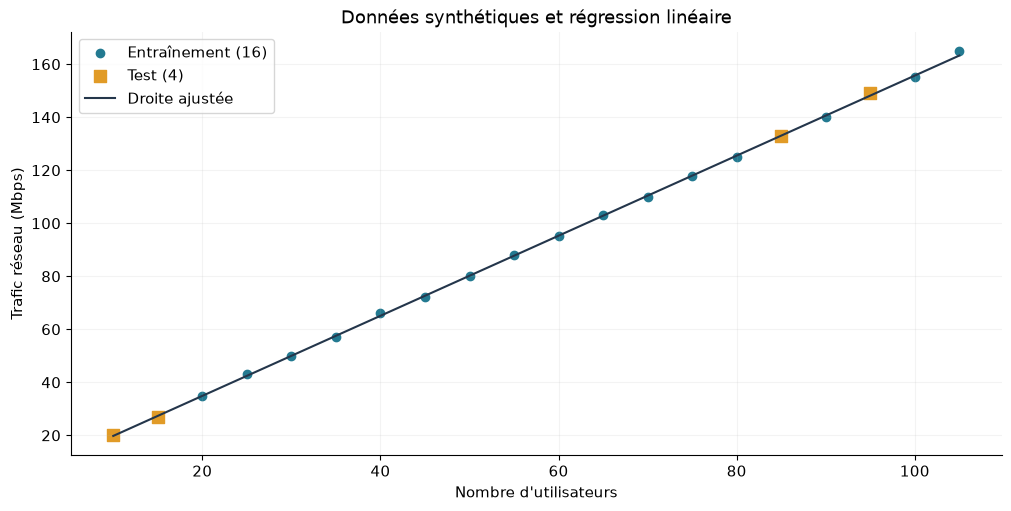

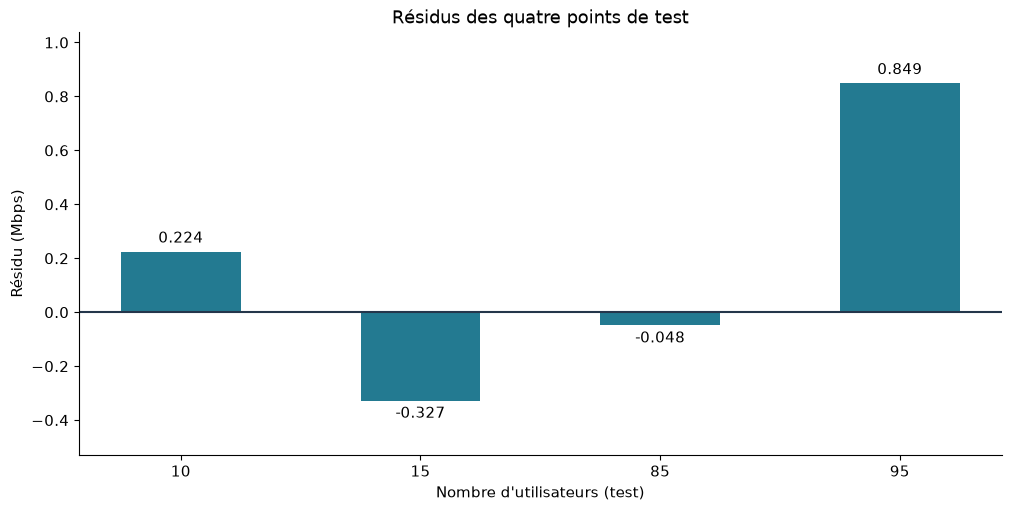

In [6]:
plt.rcParams.update({"figure.figsize": (10, 5), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
fig, ax = plt.subplots(layout="constrained")
ax.scatter(X_train["utilisateurs"], y_train, color="#237a91", label="Entraînement (16)")
ax.scatter(X_test["utilisateurs"], y_test, color="#e19b27", marker="s", s=80, label="Test (4)")
grid = pd.DataFrame({"utilisateurs": np.linspace(10, 105, 100)})
ax.plot(grid["utilisateurs"], model.predict(grid), color="#24364b", label="Droite ajustée")
ax.set(xlabel="Nombre d'utilisateurs", ylabel="Trafic réseau (Mbps)",
       title="Données synthétiques et régression linéaire")
ax.legend(); ax.grid(alpha=.15)
plt.show()

fig, ax = plt.subplots(layout="constrained")
tri = resultats.sort_values("utilisateurs")
bars = ax.bar(tri["utilisateurs"].astype(str), tri["residu_mbps"], color="#237a91", width=.5)
ax.axhline(0, color="#24364b"); ax.bar_label(bars, fmt="%.3f", padding=4)
ax.set(xlabel="Nombre d'utilisateurs (test)", ylabel="Résidu (Mbps)", ylim=(-.53, 1.04),
       title="Résidus des quatre points de test")
plt.show()

## 6. Reprendre le scénario du support
À 110 utilisateurs, le modèle sort légèrement de la plage observée, qui s'arrête à 105. Le trafic de 220 Mbps est simulé. Le seuil absolu de 40 Mbps est arbitraire et n'a pas été calibré sur des incidents.

In [7]:
trafic_attendu = float(model.predict(pd.DataFrame({"utilisateurs": [110]}))[0])
trafic_observe = 220
residu = trafic_observe - trafic_attendu
seuil = 40
print(f"Trafic attendu : {trafic_attendu:.6f} Mbps")
print(f"Trafic simulé : {trafic_observe:.2f} Mbps")
print(f"Résidu : {residu:.6f} Mbps")
print("À investiguer :", abs(residu) > seuil)
print("Ce signal ne confirme pas une cyberattaque.")

Trafic attendu : 170.805912 Mbps
Trafic simulé : 220.00 Mbps
Résidu : 49.194088 Mbps
À investiguer : True
Ce signal ne confirme pas une cyberattaque.


## 7. Faire varier le trafic simulé
Les valeurs 160, 180 et 120 sont des ajouts lors de la reproduction, pour compléter l'exercice d'analyse. Le cas 220 est celui montré dans le PDF. La règle strictement supérieure au seuil considère les hausses et les baisses.

In [8]:
scenarios = pd.DataFrame({
    "utilisateurs": [110] * 4,
    "trafic_observe_mbps": [160, 180, 220, 120],
    "provenance": ["extension_reproduction", "extension_reproduction",
                   "cas_documente_source", "extension_reproduction"],
})
scenarios["trafic_predit_mbps"] = trafic_attendu
scenarios["residu_mbps"] = scenarios["trafic_observe_mbps"] - trafic_attendu
scenarios["seuil_absolu_mbps"] = seuil
scenarios["a_investiguer"] = scenarios["residu_mbps"].abs() > seuil
display(scenarios)
print("Un résidu exactement égal à +40 ou -40 ne déclenche pas la règle stricte.")

,utilisateurs,trafic_observe_mbps,provenance,trafic_predit_mbps,residu_mbps,seuil_absolu_mbps,a_investiguer
0,110,160,extension_reproduction,170.805912,-10.805912,40,False
1,110,180,extension_reproduction,170.805912,9.194088,40,False
2,110,220,cas_documente_source,170.805912,49.194088,40,True
3,110,120,extension_reproduction,170.805912,-50.805912,40,True


Un résidu exactement égal à +40 ou -40 ne déclenche pas la règle stricte.


## Conclusion et limites
Le modèle fournit une référence simple et lisible. Sur ces données presque linéaires, les erreurs sont faibles, mais quatre observations de test ne permettent pas de conclure sur du trafic réel. Il n'existe ni étiquette d'attaque ni historique temporel dans ce jeu.

Une investigation demanderait de relier les écarts aux flux, applications, authentifications et événements planifiés. Une extension réaliste devrait collecter un historique daté, tester une validation chronologique, comparer plusieurs références et calibrer le seuil sur des données de validation distinctes. Ces extensions ne sont pas réalisées ici.

Références : [LinearRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html), [train_test_split](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html), [métriques de régression](https://scikit-learn.org/stable/modules/model_evaluation.html#regression-metrics).